In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import log_loss
from lightgbm import LGBMClassifier
import xgboost as xgb
import itertools

In [319]:
train = pd.read_csv('train_set.csv')
print(train.head())

             ID  Month  Day_of_Month  Estimated_Departure_Time  \
0  TRAIN_000001      9             9                    1145.0   
1  TRAIN_000002      4            10                     825.0   
2  TRAIN_000003     10            19                     954.0   
3  TRAIN_000004      4            29                    1920.0   
4  TRAIN_000005      5            26                     635.0   

   Estimated_Arrival_Time  Cancelled  Diverted Origin_Airport  \
0                  1316.0          0         0            SEA   
1                  1005.0          0         0            DEN   
2                  1158.0          0         0            CLT   
3                  2247.0          0         0            EWR   
4                  1100.0          0         0            PHX   

   Origin_Airport_ID    Origin_State Destination_Airport  \
0              14747      Washington                 MFR   
1              11292        Colorado                 OAK   
2              11057  North Caro

In [320]:
train.describe()

,Month,Day_of_Month,Estimated_Departure_Time,Estimated_Arrival_Time,Cancelled,Diverted,Origin_Airport_ID,Destination_Airport_ID,Distance,Carrier_ID(DOT)
count,800000.000000,800000.000000,712923.000000,712857.000000,800000.0,800000.0,800000.000000,800000.000000,800000.00000,712622.000000
mean,6.946174,15.768371,1341.106616,1493.407178,0.0,0.0,12696.499434,12701.436865,784.53143,19997.460947
std,3.463210,8.765089,489.822736,520.791742,0.0,0.0,1515.129235,1515.325118,590.66340,404.558035
min,1.000000,1.000000,1.000000,1.000000,0.0,0.0,10135.000000,10135.000000,16.00000,19393.000000
25%,4.000000,8.000000,925.000000,1105.000000,0.0,0.0,11292.000000,11292.000000,351.00000,19790.000000
50%,7.000000,16.000000,1333.000000,1524.000000,0.0,0.0,12889.000000,12889.000000,623.00000,19977.000000
75%,10.000000,23.000000,1742.000000,1924.000000,0.0,0.0,14057.000000,14057.000000,1020.00000,20378.000000
max,12.000000,31.000000,2359.000000,2400.000000,0.0,0.0,16869.000000,16869.000000,5095.00000,21171.000000


In [321]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800000 entries, 0 to 799999
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        800000 non-null  object 
 1   Month                     800000 non-null  int64  
 2   Day_of_Month              800000 non-null  int64  
 3   Estimated_Departure_Time  712923 non-null  float64
 4   Estimated_Arrival_Time    712857 non-null  float64
 5   Cancelled                 800000 non-null  int64  
 6   Diverted                  800000 non-null  int64  
 7   Origin_Airport            800000 non-null  object 
 8   Origin_Airport_ID         800000 non-null  int64  
 9   Origin_State              712793 non-null  object 
 10  Destination_Airport       800000 non-null  object 
 11  Destination_Airport_ID    800000 non-null  int64  
 12  Destination_State         712556 non-null  object 
 13  Distance                  800000 non-null  f

In [322]:
print(train.isnull().sum())

ID                               0
Month                            0
Day_of_Month                     0
Estimated_Departure_Time     87077
Estimated_Arrival_Time       87143
Cancelled                        0
Diverted                         0
Origin_Airport                   0
Origin_Airport_ID                0
Origin_State                 87207
Destination_Airport              0
Destination_Airport_ID           0
Destination_State            87444
Distance                         0
Airline                      87301
Carrier_Code(IATA)           87112
Carrier_ID(DOT)              87378
Tail_Number                      0
Delay                       595935
dtype: int64


In [323]:
valid_rows = train.dropna(subset=['Airline', 'Carrier_ID(DOT)']).drop_duplicates(subset=['Airline', 'Carrier_ID(DOT)'])
name_to_id = dict(zip(valid_rows['Airline'], valid_rows['Carrier_ID(DOT)']))
id_to_name = dict(zip(valid_rows['Carrier_ID(DOT)'], valid_rows['Airline']))
def fill_airline(row):
    if pd.isna(row['Airline']):
        if pd.notna(row['Carrier_ID(DOT)']) and row['Carrier_ID(DOT)'] in id_to_name:
            return id_to_name[row['Carrier_ID(DOT)']]
    return row['Airline']
def fill_id(row):
    if pd.isna(row['Carrier_ID(DOT)']):
        if pd.notna(row['Airline']) and row['Airline'] in name_to_id:
            return name_to_id[row['Airline']]
    return row['Carrier_ID(DOT)']
train['Airline'] = train.apply(fill_airline, axis=1)
train['Carrier_ID(DOT)'] = train.apply(fill_id, axis=1)
print("Airline 결측치 개수:", train['Airline'].isnull().sum())
print("Carrier_ID(DOT) 결측치 개수:", train['Carrier_ID(DOT)'].isnull().sum())

Airline 결측치 개수: 9545
Carrier_ID(DOT) 결측치 개수: 9545


In [324]:
def to_days(x):
    month_to_days = {1:0, 2:31, 3:60, 4:91, 5:121, 6:152, 7:182, 8:213, 9:244, 10:274, 11:305, 12:335}
    return month_to_days[x]
train['date'] = train['Month'].apply(lambda x: to_days(x)) + train['Day_of_Month']
print(train['date'].isnull().sum())

0


In [325]:
print(train.nunique())

ID                          800000
Month                           12
Day_of_Month                    31
Estimated_Departure_Time      1361
Estimated_Arrival_Time        1422
Cancelled                        1
Diverted                         1
Origin_Airport                 374
Origin_Airport_ID              374
Origin_State                    52
Destination_Airport            375
Destination_Airport_ID         375
Destination_State               52
Distance                      1594
Airline                         28
Carrier_Code(IATA)              11
Carrier_ID(DOT)                 28
Tail_Number                   6422
Delay                            2
date                           365
dtype: int64


In [326]:
def to_minutes(x):
    if pd.isna(x):
        return np.nan
    s = str(int(x))
    if len(s) <= 2:
        hours = 0
        mins = int(s)
    else:
        hours = int(s[:-2])
        mins = int(s[-2:])
    return hours * 60 + mins
train['EDT_min'] = train['Estimated_Departure_Time'].apply(to_minutes)
train['EAT_min'] = train['Estimated_Arrival_Time'].apply(to_minutes)
train = train.dropna(subset=['EDT_min', 'EAT_min'], how='all').reset_index(drop=True)
time_sum = defaultdict(int)
time_count = defaultdict(int)
mask_both = train['EDT_min'].notna() & train['EAT_min'].notna()
for _, row in train.loc[mask_both].iterrows():
    oaid = row['Origin_Airport_ID']
    daid = row['Destination_Airport_ID']
    diff = int(row['EAT_min']) - int(row['EDT_min'])
    diff_mod = diff % 1440
    time_sum[(oaid, daid)] += diff_mod
    time_count[(oaid, daid)] += 1
avg_time = {}
for key in time_sum:
    avg_time[key] = time_sum[key] // time_count[key]
mask_EDT_missing = train['EDT_min'].isna() & train['EAT_min'].notna()
for idx, row in train.loc[mask_EDT_missing].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EAT_min']) - avg_time[key]) % 1440
        train.at[idx, 'EDT_min'] = recov
mask_EAT_missing = train['EAT_min'].isna() & train['EDT_min'].notna()
for idx, row in train.loc[mask_EAT_missing].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EDT_min']) + avg_time[key]) % 1440
        train.at[idx, 'EAT_min'] = recov
train['Estimated_Departure_Time'] = train['EDT_min']
train['Estimated_Arrival_Time']   = train['EAT_min']

In [327]:
train=train.drop(columns=['ID',"EDT_min","EAT_min",'Origin_Airport_ID', 'Destination_Airport_ID','Origin_State','Destination_State','Carrier_Code(IATA)',"Month","Day_of_Month","Cancelled","Diverted","Carrier_ID(DOT)"])

In [328]:
print(train.nunique())

Estimated_Departure_Time    1401
Estimated_Arrival_Time      1431
Origin_Airport               374
Destination_Airport          375
Distance                    1594
Airline                       28
Tail_Number                 6421
Delay                          2
date                         365
dtype: int64


In [329]:
print(train.isnull().sum())

Estimated_Departure_Time        28
Estimated_Arrival_Time          22
Origin_Airport                   0
Destination_Airport              0
Distance                         0
Airline                       9428
Tail_Number                      0
Delay                       588949
date                             0
dtype: int64


In [330]:
train = train.dropna()
print(train.isnull().sum())

Estimated_Departure_Time    0
Estimated_Arrival_Time      0
Origin_Airport              0
Destination_Airport         0
Distance                    0
Airline                     0
Tail_Number                 0
Delay                       0
date                        0
dtype: int64


In [331]:
print(train['Delay'].unique())

['Not_Delayed' 'Delayed']


In [332]:
train['Delay'] = train['Delay'].map({'Not_Delayed': 0, 'Delayed': 1})

In [333]:
print(train.nunique())

Estimated_Departure_Time    1328
Estimated_Arrival_Time      1393
Origin_Airport               373
Destination_Airport          373
Distance                    1566
Airline                       28
Tail_Number                 6296
Delay                          2
date                         365
dtype: int64


In [334]:
print(len(train))

199331


In [335]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199331 entries, 5 to 790627
Data columns (total 9 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Estimated_Departure_Time  199331 non-null  float64
 1   Estimated_Arrival_Time    199331 non-null  float64
 2   Origin_Airport            199331 non-null  object 
 3   Destination_Airport       199331 non-null  object 
 4   Distance                  199331 non-null  float64
 5   Airline                   199331 non-null  object 
 6   Tail_Number               199331 non-null  object 
 7   Delay                     199331 non-null  int64  
 8   date                      199331 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 15.2+ MB


In [336]:
con_cols = ['Estimated_Departure_Time', 'Distance', 'date','Estimated_Arrival_Time']
cat_cols=['Origin_Airport', 'Destination_Airport', 'Airline', 'Tail_Number']
target_col=["Delay"]

In [337]:
train[con_cols].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Estimated_Departure_Time,199331.0,802.608591,295.347631,0.0,545.0,790.0,1050.0,1439.0
Distance,199331.0,780.400289,588.701163,16.0,349.0,621.0,1014.0,5095.0
date,199331.0,197.505636,106.232757,1.0,106.0,209.0,290.0,366.0
Estimated_Arrival_Time,199331.0,895.953851,310.693344,0.0,653.0,900.0,1150.0,1440.0


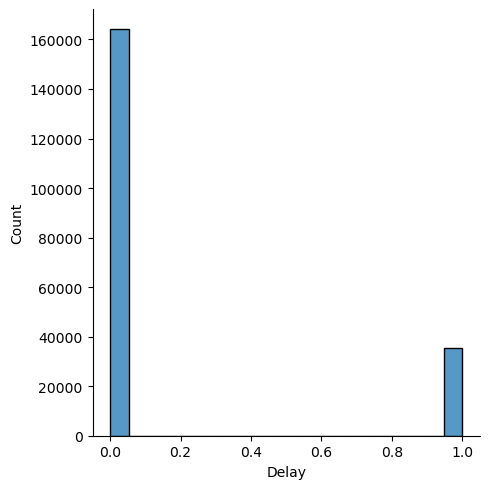

In [338]:
sns.displot(train['Delay'])
plt.show()

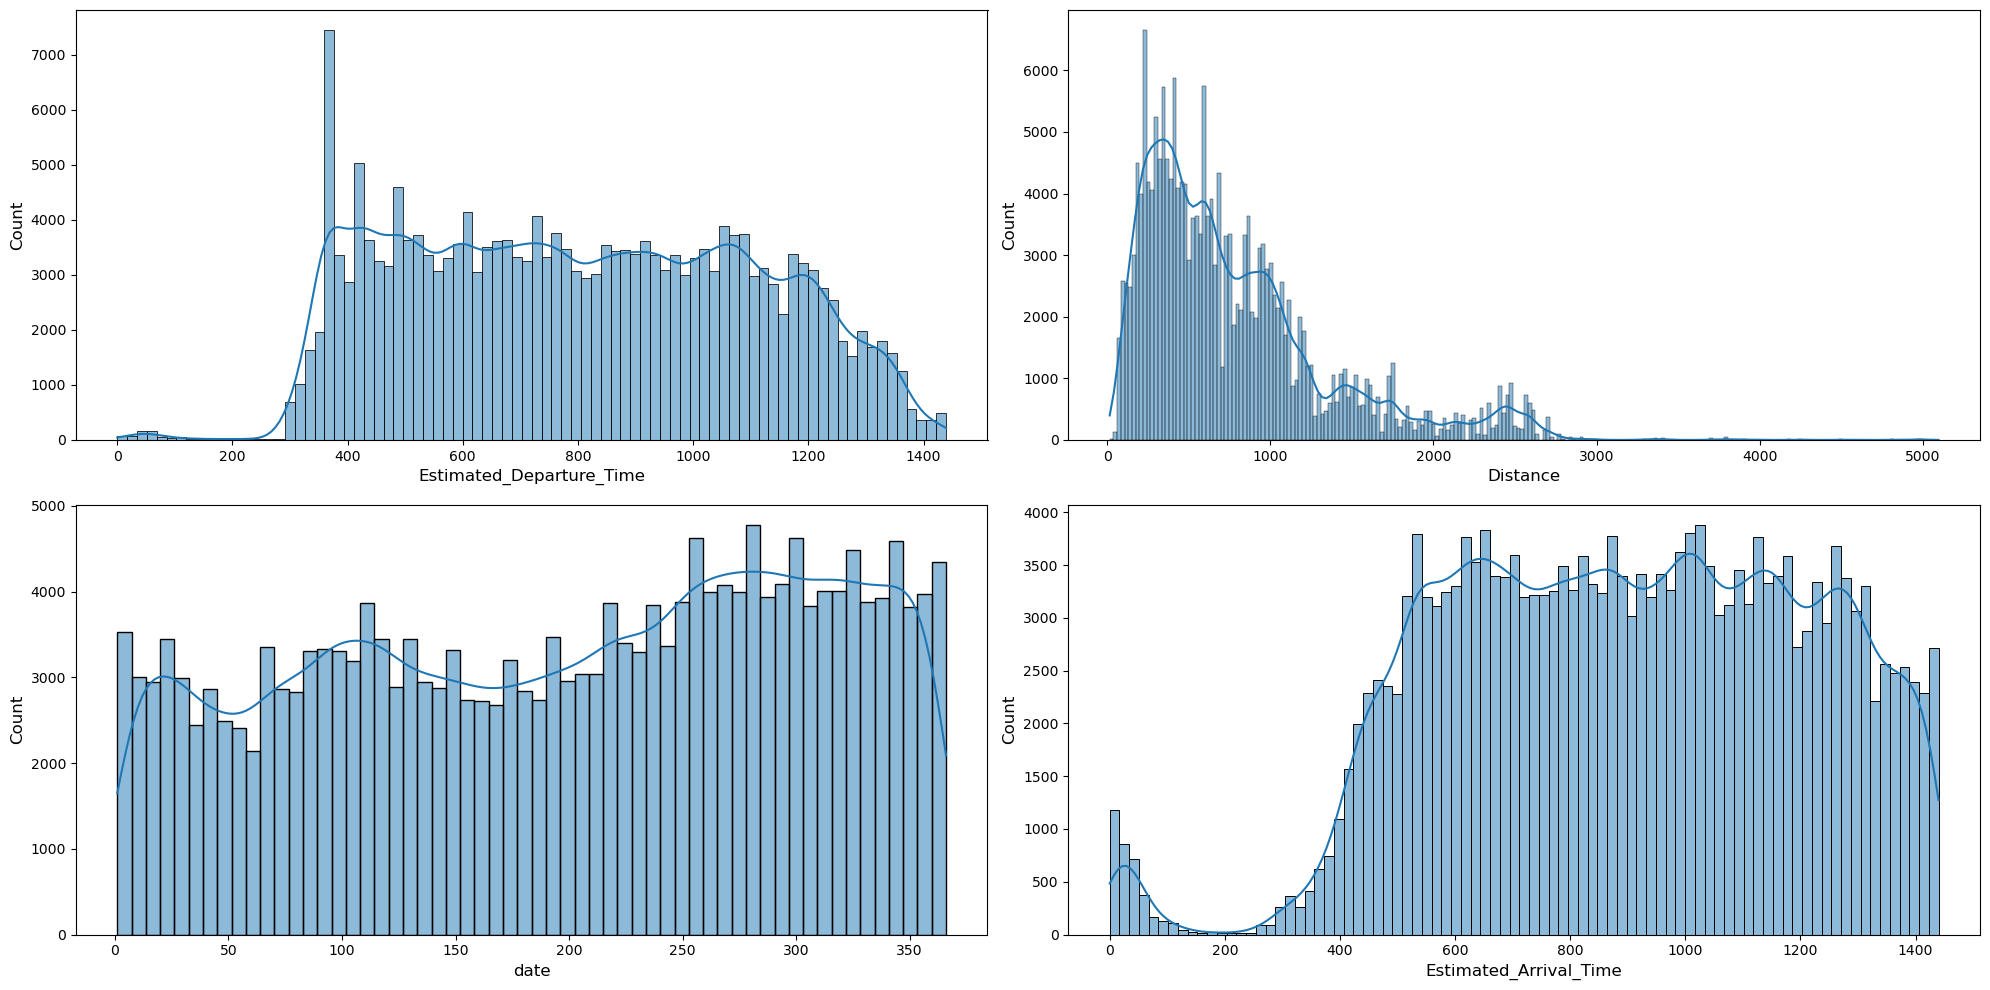

In [339]:
plt.figure(figsize=(20, 10))
for i, feature in enumerate(con_cols,1):
    plt.subplot(2,2,i)
    sns.histplot(x=feature, kde=True, data=train)
    plt.ylabel("Count", fontsize=12)
    plt.xlabel(feature, fontsize=12)
    plt.tight_layout()

In [340]:
# plt.figure(figsize=(20, 10))
# for i, feature in enumerate(cat_cols,1):
#     plt.subplot(2,2,i)
#     sns.countplot(x=feature, data=train)
#     plt.ylabel("Count", fontsize=12)
#     plt.xlabel(feature, fontsize=12)
#     plt.tight_layout()

In [ ]:
# SAMPLE_SIZE = 10000
# train_small = train.sample(n=SAMPLE_SIZE, random_state=42)
# x_small = train_small.drop(columns=['Delay'])
# y_small = train_small['Delay']
# x_train, x_test, y_train, y_test = train_test_split(x_small, y_small,test_size=0.2,random_state=42)
# print("Train 크기:", x_train.shape, " / Test 크기:", x_test.shape)

Train 크기: (8000, 8)  / Test 크기: (2000, 8)


In [ ]:
# ohe_air = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# ohe_air.fit(x_train[['Airline']])
# air_train_np = ohe_air.transform(x_train[['Airline']])
# air_test_np  = ohe_air.transform(x_test[['Airline']])
# ohe_air_cols = ohe_air.get_feature_names_out(['Airline'])
# df_air_train = pd.DataFrame(air_train_np, index=x_train.index, columns=ohe_air_cols)
# df_air_test  = pd.DataFrame(air_test_np,  index=x_test.index,  columns=ohe_air_cols)
# x_train = pd.concat([x_train, df_air_train], axis=1)
# x_train.drop(columns=['Airline'], inplace=True)
# x_test  = pd.concat([x_test, df_air_test], axis=1)
# x_test.drop(columns=['Airline'], inplace=True)


# other_cols = [c for c in cat_cols if c != 'Airline']
# for col in other_cols:
#     le = LabelEncoder()
#     x_train[col] = le.fit_transform(x_train[col].astype(str))
#     for lbl in np.unique(x_test[col].astype(str)):
#         if lbl not in le.classes_:
#             le.classes_ = np.append(le.classes_, lbl)
#     x_test[col] = le.transform(x_test[col].astype(str))

In [ ]:
# def sanitize_columns(df):
#     df.columns = df.columns.str.replace(r"[^\w]", "_", regex=True)
#     return df
# x_train = sanitize_columns(x_train)
# x_test  = sanitize_columns(x_test)

In [345]:
# bad_cols = [col for col in x_train.columns if x_train[col].dtype == 'object']
# print("Object 타입으로 남아 있는 컬럼:", bad_cols)

In [346]:
# num_missing = x_train.isna().sum().sum()
# print(f"▶ x_train 전체 NaN 개수: {num_missing}")
# print("▶ 컬럼별 NaN 개수:")
# print(x_train.isna().sum())
# has_infs = np.isinf(x_train.values).sum()
# print(f"▶ x_train에 inf 혹은 -inf 개수: {has_infs}")
# bad_idx_nan = x_train.index[x_train.isna().any(axis=1)]
# print(f"▶ NaN/inf가 있는 행 개수: {len(bad_idx_nan)}")

In [347]:
# n_splits = 5
# skf = StratifiedKFold(
#     n_splits=n_splits,
#     shuffle=True,
#     random_state=42
# )
# models = {
#     'RandomForest': RandomForestClassifier(
#         n_estimators=100, max_depth=None, random_state=42, n_jobs=-1
#     ),
#     'XGBoost': XGBClassifier(
#         n_estimators=100, max_depth=6, learning_rate=0.1,
#         objective='binary:logistic', use_label_encoder=False,
#         eval_metric='logloss', random_state=42, n_jobs=-1
#     ),
#     'DecisionTree': DecisionTreeClassifier(
#         max_depth=None, random_state=42
#     )
# }
# cv_results = {}
# for name, model in models.items():
#     print(f"\n>>> [{name}] 5-Fold Stratified CV on Train set 시작 ...")
#     scores = cross_validate(
#         estimator=model,
#         X=x_train,
#         y=y_train,
#         cv=skf,
#         scoring='neg_log_loss',
#         return_train_score=False,
#         n_jobs=-1,
#         verbose=1
#     )
    
#     neg_ll_array = scores['test_score']  
#     mean_ll = -np.mean(neg_ll_array)     
#     std_ll  = np.std(neg_ll_array)        

#     cv_results[name] = {
#         'neg_logloss_per_fold': neg_ll_array,
#         'mean_logloss': mean_ll,
#         'std_logloss':  std_ll
#     }
#     print(f"[{name}]  Fold별 neg_log_loss: {np.round(neg_ll_array, 4)}")
#     print(f"[{name}]  평균 Log-Loss: {mean_ll:.4f}  (+/− {std_ll:.4f})")
# print("\n===== 5-Fold CV 결과 비교 (Train 세트 기준) =====")
# for name, res in cv_results.items():
#     print(f"{name:<12} → Mean Log-Loss: {res['mean_logloss']:.4f}  (+/− {res['std_logloss']:.4f})")

In [348]:
# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count 
# print(f"Negative (Delay=0) 개수: {neg_count}, Positive (Delay=1) 개수: {pos_count}")
# print(f"XGBoost scale_pos_weight 로 사용할 값: {scale_pos_weight:.2f}")
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# rf = RandomForestClassifier(
#     random_state=42,
#     n_jobs=-1,
#     class_weight='balanced' 
# param_grid_rf = {
#     'n_estimators':    [100, 200],      
#     'max_depth':       [None, 10, 20],   
#     'min_samples_leaf': [1, 5, 10],         
# })
# grid_rf = GridSearchCV(
#     estimator=rf,
#     param_grid=param_grid_rf,
#     scoring='neg_log_loss',    
#     cv=skf,
#     n_jobs=-1,
#     verbose=1,
#     return_train_score=False
# )
# print("\n>>> RandomForest 하이퍼파라미터 튜닝 시작 ...")
# grid_rf.fit(x_train, y_train)
# best_params_rf = grid_rf.best_params_
# best_score_rf  = -grid_rf.best_score_  
# print(f"[RandomForest] 최적 파라미터: {best_params_rf}")
# print(f"[RandomForest] CV 평균 Log-Loss: {best_score_rf:.4f}")
# xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1
# )
# param_grid_xgb = {
#     'n_estimators':    [100, 200], 
#     'max_depth':       [4, 6, 8],
#     'learning_rate':   [0.01, 0.1, 0.2],
#     'subsample':       [0.7, 1.0],
#     'colsample_bytree': [0.7, 1.0],
#     'scale_pos_weight': [scale_pos_weight, 1]  
# }
# grid_xgb = GridSearchCV(
#     estimator=xgb,
#     param_grid=param_grid_xgb,
#     scoring='neg_log_loss',
#     cv=skf,
#     n_jobs=-1,
#     verbose=1,
#     return_train_score=False
# )
# print("\n>>> XGBoost 하이퍼파라미터 튜닝 시작 ...")
# grid_xgb.fit(x_train, y_train)
# best_params_xgb = grid_xgb.best_params_
# best_score_xgb  = -grid_xgb.best_score_
# print(f"[XGBoost] 최적 파라미터: {best_params_xgb}")
# print(f"[XGBoost] CV 평균 Log-Loss: {best_score_xgb:.4f}")
# print("\n===== 하이퍼파라미터 튜닝 결과 (Log-Loss 관점) =====")
# print(f"RandomForest → CV Log-Loss: {best_score_rf:.4f}")
# print(f"XGBoost       → CV Log-Loss: {best_score_xgb:.4f}")
# final_rf = RandomForestClassifier(
#     **best_params_rf,
#     random_state=42,
#     n_jobs=-1,
#     class_weight='balanced'
# )
# final_rf.fit(x_train, y_train)
# proba_rf_holdout = final_rf.predict_proba(x_test)
# ll_rf_holdout = log_loss(y_test, proba_rf_holdout)
# final_xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     **best_params_xgb
# )
# final_xgb.fit(x_train, y_train)
# proba_xgb_holdout = final_xgb.predict_proba(x_test)
# ll_xgb_holdout = log_loss(y_test, proba_xgb_holdout)
# print("\n===== Hold-out 세트 최종 평가 =====")
# print(f"RandomForest Hold-out Log-Loss: {ll_rf_holdout:.4f}")
# print(f"XGBoost       Hold-out Log-Loss: {ll_xgb_holdout:.4f}")

In [ ]:
# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1
# )
# param_dist = {
#     'n_estimators':     [100, 200, 300, 500],
#     'max_depth':        [3, 4, 6, 8, 10],
#     'learning_rate':    [0.01, 0.03, 0.05, 0.1, 0.2],
#     'subsample':        [0.6, 0.7, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
#     'gamma':            [0, 0.1, 0.2, 0.5],
#     'reg_alpha':        [0, 0.1, 0.5, 1.0],
#     'reg_lambda':       [1.0, 1.5, 2.0, 3.0],
#     'scale_pos_weight': [1.0]
# }
# rand_search = RandomizedSearchCV(
#     estimator=xgb,
#     param_distributions=param_dist,
#     scoring='neg_log_loss',     
#     cv=skf,
#     n_iter=80,             
#     random_state=42,
#     n_jobs=-1,
#     verbose=2,
#     return_train_score=False
# )
# print(">>> XGBoost RandomizedSearchCV 시작 ...")
# rand_search.fit(x_train, y_train)
# best_params = rand_search.best_params_
# best_score  = -rand_search.best_score_  
# print("\n[XGBoost] 최적 파라미터:")
# print(best_params)
# print(f"[XGBoost] CV 평균 Log-Loss: {best_score:.4f}")
# final_xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     **best_params
# )
# final_xgb.fit(x_train, y_train)
# proba_holdout = final_xgb.predict_proba(x_test)
# final_ll_holdout = log_loss(y_test, proba_holdout)
# print(f"최종 Hold-out 세트 Log-Loss: {final_ll_holdout:.4f}")

>>> XGBoost RandomizedSearchCV 시작 ...
Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [19:58:56] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



[XGBoost] 최적 파라미터:
{'subsample': 0.6, 'scale_pos_weight': 1.0, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}
[XGBoost] CV 평균 Log-Loss: 0.4642


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [19:58:56] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


최종 Hold-out 세트 Log-Loss: 0.4348


In [ ]:
# bad_cols = [c for c in x_train.columns if re.search(r"[^\w]", c)]
# print("문제가 되는 컬럼들:", bad_cols)

문제가 되는 컬럼들: []


In [ ]:
# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# fixed_params_xgb = {
#     'n_estimators':     300,
#     'max_depth':        4,
#     'learning_rate':    0.01,
#     'subsample':        0.6,
#     'colsample_bytree': 0.7,
#     'gamma':            0.1,
#     'reg_alpha':        0.1,
#     'reg_lambda':       2.0,
#     'scale_pos_weight': 1.0,
#     'objective':        'binary:logistic',
#     'eval_metric':      'logloss',
#     'random_state':     42,
#     'n_jobs':           -1
# }
# model_xgb = XGBClassifier(**fixed_params_xgb)
# fixed_params_lgb = {
#     'n_estimators':     300,
#     'max_depth':        4,
#     'learning_rate':    0.01,
#     'subsample':        0.6,
#     'colsample_bytree': 0.7,
#     'reg_alpha':        0.1,
#     'reg_lambda':       2.0,
#     'scale_pos_weight': 1.0,
#     'random_state':     42,
#     'n_jobs':           -1
# }
# model_lgb = LGBMClassifier(**fixed_params_lgb)
# cv_xgb = cross_validate(
#     estimator=model_xgb,
#     X=x_train,
#     y=y_train,
#     cv=skf,
#     scoring='neg_log_loss',
#     return_train_score=False,
#     n_jobs=-1
# )
# mean_ll_xgb = -np.mean(cv_xgb['test_score'])
# std_ll_xgb  = np.std(cv_xgb['test_score'])
# print(f"[XGBoost CV] Mean Log-Loss: {mean_ll_xgb:.4f} (±{std_ll_xgb:.4f})")
# cv_lgb = cross_validate(
#     estimator=model_lgb,
#     X=x_train,
#     y=y_train,
#     cv=skf,
#     scoring='neg_log_loss',
#     return_train_score=False,
#     n_jobs=-1
# )
# mean_ll_lgb = -np.mean(cv_lgb['test_score'])
# std_ll_lgb  = np.std(cv_lgb['test_score'])
# print(f"[LightGBM CV] Mean Log-Loss: {mean_ll_lgb:.4f} (±{std_ll_lgb:.4f})\n")
# model_xgb.fit(x_train, y_train)
# proba_xgb = model_xgb.predict_proba(x_test)
# ll_xgb    = log_loss(y_test, proba_xgb)
# acc_xgb   = accuracy_score(y_test, np.argmax(proba_xgb, axis=1))
# print(f"[XGBoost 단일] Hold-out Log-Loss: {ll_xgb:.4f}, Accuracy: {acc_xgb:.4f}")
# model_lgb.fit(x_train, y_train)
# proba_lgb = model_lgb.predict_proba(x_test)
# ll_lgb    = log_loss(y_test, proba_lgb)
# acc_lgb   = accuracy_score(y_test, np.argmax(proba_lgb, axis=1))
# print(f"[LightGBM 단일] Hold-out Log-Loss: {ll_lgb:.4f}, Accuracy: {acc_lgb:.4f}\n")
# ensemble_proba = (proba_xgb + proba_lgb) / 2.0
# ll_ensemble   = log_loss(y_test, ensemble_proba)
# acc_ensemble  = accuracy_score(y_test, np.argmax(ensemble_proba, axis=1))
# print(f"[앙상블(XGB+LGB 평균)] Hold-out Log-Loss: {ll_ensemble:.4f}, Accuracy: {acc_ensemble:.4f}\n")
# n_models = 10
# seeds    = [11, 22, 33, 44, 55, 66, 77, 88, 99, 100]
# bag_proba = np.zeros((x_test.shape[0], 2), dtype=float)
# print(">>> Bagging 10개 XGB 앙상블 시작 ...")
# for seed in seeds:
#     params = fixed_params_xgb.copy()
#     params['random_state'] = seed
#     m = XGBClassifier(**params)
#     m.fit(x_train, y_train)
#     bag_proba += m.predict_proba(x_test)
# bag_proba /= n_models
# ll_bag = log_loss(y_test, bag_proba)
# acc_bag = accuracy_score(y_test, np.argmax(bag_proba, axis=1))
# print(f"[Bagging 10 XGB] Hold-out Log-Loss: {ll_bag:.4f}, Accuracy: {acc_bag:.4f}")

[XGBoost CV] Mean Log-Loss: 0.4642 (±0.0046)
[LightGBM CV] Mean Log-Loss: 0.4655 (±0.0049)

[XGBoost 단일] Hold-out Log-Loss: 0.4348, Accuracy: 0.8395
[LightGBM] [Info] Number of positive: 1486, number of negative: 6514
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000849 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1686
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.185750 -> initscore=-1.477866
[LightGBM] [Info] Start training from score -1.477866
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

In [ ]:
# x = train.drop(columns=['Delay'])
# y = train['Delay']
# x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)
# ohe_air = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# ohe_air.fit(x_train[['Airline']])
# air_train_np = ohe_air.transform(x_train[['Airline']])
# air_test_np  = ohe_air.transform(x_test[['Airline']])
# ohe_air_cols = ohe_air.get_feature_names_out(['Airline'])
# df_air_train = pd.DataFrame(air_train_np, index=x_train.index, columns=ohe_air_cols)
# df_air_test  = pd.DataFrame(air_test_np,  index=x_test.index,  columns=ohe_air_cols)
# x_train = pd.concat([x_train, df_air_train], axis=1)
# x_train.drop(columns=['Airline'], inplace=True)
# x_test  = pd.concat([x_test, df_air_test], axis=1)
# x_test.drop(columns=['Airline'], inplace=True)

# other_cols = [c for c in cat_cols if c != 'Airline']
# for col in other_cols:
#     le = LabelEncoder()
#     x_train[col] = le.fit_transform(x_train[col].astype(str))
#     for lbl in np.unique(x_test[col].astype(str)):
#         if lbl not in le.classes_:
#             le.classes_ = np.append(le.classes_, lbl)
#     x_test[col] = le.transform(x_test[col].astype(str))

# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1
# )
# param_dist = {
#     'n_estimators':     [100, 200, 300, 500],
#     'max_depth':        [3, 4, 6, 8, 10],
#     'learning_rate':    [0.01, 0.03, 0.05, 0.1, 0.2],
#     'subsample':        [0.6, 0.7, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
#     'gamma':            [0, 0.1, 0.2, 0.5],
#     'reg_alpha':        [0, 0.1, 0.5, 1.0],
#     'reg_lambda':       [1.0, 1.5, 2.0, 3.0],
#     'scale_pos_weight': [scale_pos_weight, 1.0]
# }
# rand_search = RandomizedSearchCV(
#     estimator=xgb,
#     param_distributions=param_dist,
#     scoring='neg_log_loss',     
#     cv=skf,
#     n_iter=80,             
#     random_state=42,
#     n_jobs=-1,
#     verbose=2,
#     return_train_score=False
# )
# print(">>> XGBoost RandomizedSearchCV 시작 ...")
# rand_search.fit(x_train, y_train)
# best_params = rand_search.best_params_
# best_score  = -rand_search.best_score_  
# print("\n[XGBoost] 최적 파라미터:")
# print(best_params)
# print(f"[XGBoost] CV 평균 Log-Loss: {best_score:.4f}")
# final_xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     **best_params
# )
# final_xgb.fit(x_train, y_train)
# proba_holdout = final_xgb.predict_proba(x_test)
# final_ll_holdout = log_loss(y_test, proba_holdout)
# print(f"최종 Hold-out 세트 Log-Loss: {final_ll_holdout:.4f}")

>>> XGBoost RandomizedSearchCV 시작 ...
Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [18:13:22] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



[XGBoost] 최적 파라미터:
{'subsample': 1.0, 'scale_pos_weight': 1.0, 'reg_lambda': 1.5, 'reg_alpha': 0.5, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}
[XGBoost] CV 평균 Log-Loss: 0.4378


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [18:13:24] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


최종 Hold-out 세트 Log-Loss: 0.4378


In [ ]:
# train = pd.read_csv('train_set.csv')
# valid_rows = train.dropna(subset=['Airline', 'Carrier_ID(DOT)']).drop_duplicates(subset=['Airline', 'Carrier_ID(DOT)'])
# name_to_id = dict(zip(valid_rows['Airline'], valid_rows['Carrier_ID(DOT)']))
# id_to_name = dict(zip(valid_rows['Carrier_ID(DOT)'], valid_rows['Airline']))
# def fill_airline(row):
#     if pd.isna(row['Airline']):
#         if pd.notna(row['Carrier_ID(DOT)']) and row['Carrier_ID(DOT)'] in id_to_name:
#             return id_to_name[row['Carrier_ID(DOT)']]
#     return row['Airline']
# def fill_id(row):
#     if pd.isna(row['Carrier_ID(DOT)']):
#         if pd.notna(row['Airline']) and row['Airline'] in name_to_id:
#             return name_to_id[row['Airline']]
#     return row['Carrier_ID(DOT)']
# train['Airline'] = train.apply(fill_airline, axis=1)
# train['Carrier_ID(DOT)'] = train.apply(fill_id, axis=1)
# def to_days(x):
#     month_to_days = {1:0, 2:31, 3:60, 4:91, 5:121, 6:152, 7:182, 8:213, 9:244, 10:274, 11:305, 12:335}
#     return month_to_days[x]
# train['date'] = train['Month'].apply(lambda x: to_days(x)) + train['Day_of_Month']
# def to_minutes(x):
#     if pd.isna(x):
#         return np.nan
#     s = str(int(x))
#     if len(s) <= 2:
#         hours = 0
#         mins = int(s)
#     else:
#         hours = int(s[:-2])
#         mins = int(s[-2:])
#     return hours * 60 + mins
# train['EDT_min'] = train['Estimated_Departure_Time'].apply(to_minutes)
# train['EAT_min'] = train['Estimated_Arrival_Time'].apply(to_minutes)
# train = train.dropna(subset=['EDT_min', 'EAT_min'], how='all').reset_index(drop=True)
# time_sum = defaultdict(int)
# time_count = defaultdict(int)
# mask_both = train['EDT_min'].notna() & train['EAT_min'].notna()
# for _, row in train.loc[mask_both].iterrows():
#     oaid = row['Origin_Airport_ID']
#     daid = row['Destination_Airport_ID']
#     diff = int(row['EAT_min']) - int(row['EDT_min'])
#     diff_mod = diff % 1440
#     time_sum[(oaid, daid)] += diff_mod
#     time_count[(oaid, daid)] += 1
# avg_time = {}
# for key in time_sum:
#     avg_time[key] = time_sum[key] // time_count[key]
# mask_EDT_missing = train['EDT_min'].isna() & train['EAT_min'].notna()
# for idx, row in train.loc[mask_EDT_missing].iterrows():
#     key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
#     if key in avg_time:
#         recov = (int(row['EAT_min']) - avg_time[key]) % 1440
#         train.at[idx, 'EDT_min'] = recov
# mask_EAT_missing = train['EAT_min'].isna() & train['EDT_min'].notna()
# for idx, row in train.loc[mask_EAT_missing].iterrows():
#     key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
#     if key in avg_time:
#         recov = (int(row['EDT_min']) + avg_time[key]) % 1440
#         train.at[idx, 'EAT_min'] = recov
# train['Estimated_Departure_Time'] = train['EDT_min']
# train['Estimated_Arrival_Time']   = train['EAT_min']
# train=train.drop(columns=['Tail_Number','ID',"EDT_min","EAT_min",'Origin_Airport_ID', 'Destination_Airport_ID','Origin_State','Destination_State','Carrier_Code(IATA)',"Month","Day_of_Month","Cancelled","Diverted","Carrier_ID(DOT)"])
# train = train.dropna()
# train['Delay'] = train['Delay'].map({'Not_Delayed': 0, 'Delayed': 1})
# con_cols = ['Estimated_Departure_Time', 'Distance', 'date','Estimated_Arrival_Time']
# cat_cols=['Origin_Airport', 'Destination_Airport', 'Airline']
# target_col=["Delay"]

In [ ]:
# SAMPLE_SIZE = 10000
# train_small = train.sample(n=SAMPLE_SIZE, random_state=42)
# x_small = train_small.drop(columns=['Delay'])
# y_small = train_small['Delay']
# x_train, x_test, y_train, y_test = train_test_split(x_small, y_small,test_size=0.2,random_state=42)
# print("Train 크기:", x_train.shape, " / Test 크기:", x_test.shape)

Train 크기: (8000, 7)  / Test 크기: (2000, 7)


In [ ]:
# ohe_air = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# ohe_air.fit(x_train[['Airline']])
# air_train_np = ohe_air.transform(x_train[['Airline']])
# air_test_np  = ohe_air.transform(x_test[['Airline']])
# ohe_air_cols = ohe_air.get_feature_names_out(['Airline'])
# df_air_train = pd.DataFrame(air_train_np, index=x_train.index, columns=ohe_air_cols)
# df_air_test  = pd.DataFrame(air_test_np,  index=x_test.index,  columns=ohe_air_cols)
# x_train = pd.concat([x_train, df_air_train], axis=1)
# x_train.drop(columns=['Airline'], inplace=True)
# x_test  = pd.concat([x_test, df_air_test], axis=1)
# x_test.drop(columns=['Airline'], inplace=True)


# other_cols = [c for c in cat_cols if c != 'Airline']
# for col in other_cols:
#     le = LabelEncoder()
#     x_train[col] = le.fit_transform(x_train[col].astype(str))
#     for lbl in np.unique(x_test[col].astype(str)):
#         if lbl not in le.classes_:
#             le.classes_ = np.append(le.classes_, lbl)
#     x_test[col] = le.transform(x_test[col].astype(str))
# def sanitize_columns(df):
#     df.columns = df.columns.str.replace(r"[^\w]", "_", regex=True)
#     return df
# x_train = sanitize_columns(x_train)
# x_test  = sanitize_columns(x_test)

In [ ]:
# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# xgb = XGBClassifier(
#     objective='binary:logistic',
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1
# )
# param_dist = {
#     'n_estimators':     [100, 200, 300, 500],
#     'max_depth':        [3, 4, 6, 8, 10],
#     'learning_rate':    [0.01, 0.03, 0.05, 0.1, 0.2],
#     'subsample':        [0.6, 0.7, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
#     'gamma':            [0, 0.1, 0.2, 0.5],
#     'reg_alpha':        [0, 0.1, 0.5, 1.0],
#     'reg_lambda':       [1.0, 1.5, 2.0, 3.0],
#     'scale_pos_weight': [1.0]
# }
# rand_search = RandomizedSearchCV(
#     estimator=xgb,
#     param_distributions=param_dist,
#     scoring='neg_log_loss',     
#     cv=skf,
#     n_iter=80,             
#     random_state=42,
#     n_jobs=-1,
#     verbose=2,
#     return_train_score=False
# )
# print(">>> XGBoost RandomizedSearchCV 시작 ...")
# rand_search.fit(x_train, y_train)
# best_params = rand_search.best_params_
# best_score  = -rand_search.best_score_  
# print("\n[XGBoost] 최적 파라미터:")
# print(best_params)
# print(f"[XGBoost] CV 평균 Log-Loss: {best_score:.4f}")
# final_xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     **best_params
# )
# final_xgb.fit(x_train, y_train)
# proba_holdout = final_xgb.predict_proba(x_test)
# final_ll_holdout = log_loss(y_test, proba_holdout)
# print(f"최종 Hold-out 세트 Log-Loss: {final_ll_holdout:.4f}")

>>> XGBoost RandomizedSearchCV 시작 ...
Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:10:12] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



[XGBoost] 최적 파라미터:
{'subsample': 0.7, 'scale_pos_weight': 1.0, 'reg_lambda': 1.5, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 1.0}
[XGBoost] CV 평균 Log-Loss: 0.4652


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:10:12] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


최종 Hold-out 세트 Log-Loss: 0.4340


In [ ]:
# train = pd.read_csv('train_set.csv')
# valid_rows = train.dropna(subset=['Airline', 'Carrier_ID(DOT)']).drop_duplicates(subset=['Airline', 'Carrier_ID(DOT)'])
# name_to_id = dict(zip(valid_rows['Airline'], valid_rows['Carrier_ID(DOT)']))
# id_to_name = dict(zip(valid_rows['Carrier_ID(DOT)'], valid_rows['Airline']))
# def fill_airline(row):
#     if pd.isna(row['Airline']):
#         if pd.notna(row['Carrier_ID(DOT)']) and row['Carrier_ID(DOT)'] in id_to_name:
#             return id_to_name[row['Carrier_ID(DOT)']]
#     return row['Airline']
# def fill_id(row):
#     if pd.isna(row['Carrier_ID(DOT)']):
#         if pd.notna(row['Airline']) and row['Airline'] in name_to_id:
#             return name_to_id[row['Airline']]
#     return row['Carrier_ID(DOT)']
# train['Airline'] = train.apply(fill_airline, axis=1)
# train['Carrier_ID(DOT)'] = train.apply(fill_id, axis=1)
# def to_days(x):
#     month_to_days = {1:0, 2:31, 3:60, 4:91, 5:121, 6:152, 7:182, 8:213, 9:244, 10:274, 11:305, 12:335}
#     return month_to_days[x]
# train['date'] = train['Month'].apply(lambda x: to_days(x)) + train['Day_of_Month']
# def to_minutes(x):
#     if pd.isna(x):
#         return np.nan
#     s = str(int(x))
#     if len(s) <= 2:
#         hours = 0
#         mins = int(s)
#     else:
#         hours = int(s[:-2])
#         mins = int(s[-2:])
#     return hours * 60 + mins
# train['EDT_min'] = train['Estimated_Departure_Time'].apply(to_minutes)
# train['EAT_min'] = train['Estimated_Arrival_Time'].apply(to_minutes)
# train = train.dropna(subset=['EDT_min', 'EAT_min'], how='all').reset_index(drop=True)
# time_sum = defaultdict(int)
# time_count = defaultdict(int)
# mask_both = train['EDT_min'].notna() & train['EAT_min'].notna()
# for _, row in train.loc[mask_both].iterrows():
#     oaid = row['Origin_Airport_ID']
#     daid = row['Destination_Airport_ID']
#     diff = int(row['EAT_min']) - int(row['EDT_min'])
#     diff_mod = diff % 1440
#     time_sum[(oaid, daid)] += diff_mod
#     time_count[(oaid, daid)] += 1
# avg_time = {}
# for key in time_sum:
#     avg_time[key] = time_sum[key] // time_count[key]
# mask_EDT_missing = train['EDT_min'].isna() & train['EAT_min'].notna()
# for idx, row in train.loc[mask_EDT_missing].iterrows():
#     key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
#     if key in avg_time:
#         recov = (int(row['EAT_min']) - avg_time[key]) % 1440
#         train.at[idx, 'EDT_min'] = recov
# mask_EAT_missing = train['EAT_min'].isna() & train['EDT_min'].notna()
# for idx, row in train.loc[mask_EAT_missing].iterrows():
#     key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
#     if key in avg_time:
#         recov = (int(row['EDT_min']) + avg_time[key]) % 1440
#         train.at[idx, 'EAT_min'] = recov
# train['Estimated_Departure_Time'] = train['EDT_min']
# train['Estimated_Arrival_Time']   = train['EAT_min']
# train=train.drop(columns=['Tail_Number','ID',"EDT_min","EAT_min",'Origin_Airport_ID', 'Destination_Airport_ID','Origin_State','Destination_State','Carrier_Code(IATA)',"Month","Day_of_Month","Cancelled","Diverted","Carrier_ID(DOT)"])
# train = train.dropna()
# train['Delay'] = train['Delay'].map({'Not_Delayed': 0, 'Delayed': 1})
# con_cols = ['Estimated_Departure_Time', 'Distance', 'date','Estimated_Arrival_Time']
# cat_cols=['Origin_Airport', 'Destination_Airport', 'Airline']
# target_col=["Delay"]
# SAMPLE_SIZE = 10000
# train_small = train.sample(n=SAMPLE_SIZE, random_state=42)
# x_small = train_small.drop(columns=['Delay'])
# y_small = train_small['Delay']
# x_train, x_test, y_train, y_test = train_test_split(x_small, y_small,test_size=0.2,random_state=42)
# print("Train 크기:", x_train.shape, " / Test 크기:", x_test.shape)

Train 크기: (8000, 7)  / Test 크기: (2000, 7)


In [ ]:
# def target_encode_train(x_train: pd.DataFrame,
#                         y_train: pd.Series,
#                         col: str,
#                         n_splits: int = 5,
#                         random_state: int = 42) -> pd.Series:
#     global_mean = y_train.mean()
#     te_column = pd.Series(index=x_train.index, dtype=float)
#     kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
#     for train_idx, val_idx in kf.split(x_train, y_train):
#         df_tr = pd.DataFrame({
#             col: x_train.iloc[train_idx][col].values,
#             'target': y_train.iloc[train_idx].values
#         })
#         means = df_tr.groupby(col)['target'].mean()
#         te_values = x_train.iloc[val_idx][col].map(means).fillna(global_mean)
#         te_column.iloc[val_idx] = te_values.values

#     return te_column.fillna(global_mean)
# def target_encode_test(x_train: pd.DataFrame,y_train: pd.Series, x_test: pd.DataFrame, col: str) -> pd.Series:
#     global_mean = y_train.mean()
#     df_all = pd.DataFrame({
#         col: x_train[col].values,
#         'target': y_train.values
#     })
#     means = df_all.groupby(col)['target'].mean()
#     te_test = x_test[col].map(means).fillna(global_mean)
#     return te_test
# x_train_enc = x_train.copy()
# x_test_enc  = x_test.copy()
# ohe_air = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# ohe_air.fit(x_train_enc[['Airline']])
# air_train_np = ohe_air.transform(x_train_enc[['Airline']])
# air_train_cols = ohe_air.get_feature_names_out(['Airline'])
# df_air_train = pd.DataFrame(air_train_np, index=x_train_enc.index, columns=air_train_cols)
# x_train_enc = pd.concat([x_train_enc, df_air_train], axis=1)
# x_train_enc.drop(columns=['Airline'], inplace=True)
# air_test_np  = ohe_air.transform(x_test_enc[['Airline']])
# df_air_test  = pd.DataFrame(air_test_np, index=x_test_enc.index, columns=air_train_cols)
# x_test_enc = pd.concat([x_test_enc, df_air_test], axis=1)
# x_test_enc.drop(columns=['Airline'], inplace=True)
# for col in ['Origin_Airport', 'Destination_Airport']:
#     x_train_enc[col + '_TE'] = target_encode_train(x_train, y_train, col, n_splits=5, random_state=42)
#     x_test_enc[col + '_TE']  = target_encode_test(x_train, y_train, x_test, col)
#     x_train_enc.drop(columns=[col], inplace=True)
#     x_test_enc.drop(columns=[col], inplace=True)

# def sanitize_columns(df: pd.DataFrame) -> pd.DataFrame:
#     df.columns = df.columns.str.replace(r"[^\w]", "_", regex=True)
#     return df
# x_train_enc = sanitize_columns(x_train_enc)
# x_test_enc  = sanitize_columns(x_test_enc)

In [ ]:
# neg_count = np.sum(y_train == 0)
# pos_count = np.sum(y_train == 1)
# scale_pos_weight = neg_count / pos_count
# skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# xgb = XGBClassifier(
#     objective='binary:logistic',
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1
# )
# param_dist = {
#     'n_estimators':     [100, 200, 300, 500],
#     'max_depth':        [3, 4, 6, 8, 10],
#     'learning_rate':    [0.01, 0.03, 0.05, 0.1, 0.2],
#     'subsample':        [0.6, 0.7, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
#     'gamma':            [0, 0.1, 0.2, 0.5],
#     'reg_alpha':        [0, 0.1, 0.5, 1.0],
#     'reg_lambda':       [1.0, 1.5, 2.0, 3.0],
#     'scale_pos_weight': [1.0, scale_pos_weight]
# }
# rand_search = RandomizedSearchCV(
#     estimator=xgb,
#     param_distributions=param_dist,
#     scoring='neg_log_loss',  
#     cv=skf,                  
#     n_iter=80,               
#     random_state=42,
#     n_jobs=-1,
#     verbose=2,
#     return_train_score=False
# )
# print(">>> [타깃 인코딩 후] XGBoost RandomizedSearchCV 시작 ...")
# rand_search.fit(x_train_enc, y_train)
# best_params = rand_search.best_params_
# best_score  = -rand_search.best_score_  
# print("\n[최적 파라미터]")
# print(best_params)
# print(f"[CV 평균 Log-Loss] {best_score:.4f}")
# final_xgb = XGBClassifier(
#     objective='binary:logistic',
#     use_label_encoder=False,
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     **best_params
# )
# final_xgb.fit(x_train_enc, y_train)
# proba_holdout    = final_xgb.predict_proba(x_test_enc)
# final_ll_holdout = log_loss(y_test, proba_holdout)

# print(f"최종 Hold-out 세트 Log-Loss: {final_ll_holdout:.4f}")

>>> [타깃 인코딩 후] XGBoost RandomizedSearchCV 시작 ...
Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:37:23] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



[최적 파라미터]
{'subsample': 0.6, 'scale_pos_weight': 1.0, 'reg_lambda': 3.0, 'reg_alpha': 1.0, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.8}
[CV 평균 Log-Loss] 0.4633


c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:37:24] WARNING: D:\bld\xgboost-split_1747336820434\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


최종 Hold-out 세트 Log-Loss: 0.4357


In [437]:
train = pd.read_csv('train_set.csv')
valid_rows = train.dropna(subset=['Airline', 'Carrier_ID(DOT)']).drop_duplicates(subset=['Airline', 'Carrier_ID(DOT)'])
name_to_id = dict(zip(valid_rows['Airline'], valid_rows['Carrier_ID(DOT)']))
id_to_name = dict(zip(valid_rows['Carrier_ID(DOT)'], valid_rows['Airline']))
def fill_airline(row):
    if pd.isna(row['Airline']):
        if pd.notna(row['Carrier_ID(DOT)']) and row['Carrier_ID(DOT)'] in id_to_name:
            return id_to_name[row['Carrier_ID(DOT)']]
    return row['Airline']
def fill_id(row):
    if pd.isna(row['Carrier_ID(DOT)']):
        if pd.notna(row['Airline']) and row['Airline'] in name_to_id:
            return name_to_id[row['Airline']]
    return row['Carrier_ID(DOT)']
train['Airline'] = train.apply(fill_airline, axis=1)
train['Carrier_ID(DOT)'] = train.apply(fill_id, axis=1)
def to_days(x):
    month_to_days = {1:0, 2:31, 3:60, 4:91, 5:121, 6:152, 7:182, 8:213, 9:244, 10:274, 11:305, 12:335}
    return month_to_days[x]
train['date'] = train['Month'].apply(lambda x: to_days(x)) + train['Day_of_Month']
def to_minutes(x):
    if pd.isna(x):
        return np.nan
    s = str(int(x))
    if len(s) <= 2:
        hours = 0
        mins = int(s)
    else:
        hours = int(s[:-2])
        mins = int(s[-2:])
    return hours * 60 + mins
train['EDT_min'] = train['Estimated_Departure_Time'].apply(to_minutes)
train['EAT_min'] = train['Estimated_Arrival_Time'].apply(to_minutes)
train = train.dropna(subset=['EDT_min', 'EAT_min'], how='all').reset_index(drop=True)
mode_EDT = train['EDT_min'].mode().iloc[0]
mode_EAT = train['EAT_min'].mode().iloc[0]
time_sum = defaultdict(int)
time_count = defaultdict(int)
mask_both = train['EDT_min'].notna() & train['EAT_min'].notna()
for _, row in train.loc[mask_both].iterrows():
    oaid = row['Origin_Airport_ID']
    daid = row['Destination_Airport_ID']
    diff = int(row['EAT_min']) - int(row['EDT_min'])
    diff_mod = diff % 1440
    time_sum[(oaid, daid)] += diff_mod
    time_count[(oaid, daid)] += 1
avg_time = {}
for key in time_sum:
    avg_time[key] = time_sum[key] // time_count[key]
mask_EDT_missing = train['EDT_min'].isna() & train['EAT_min'].notna()
for idx, row in train.loc[mask_EDT_missing].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EAT_min']) - avg_time[key]) % 1440
        train.at[idx, 'EDT_min'] = recov
mask_EAT_missing = train['EAT_min'].isna() & train['EDT_min'].notna()
for idx, row in train.loc[mask_EAT_missing].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EDT_min']) + avg_time[key]) % 1440
        train.at[idx, 'EAT_min'] = recov
train['Estimated_Departure_Time'] = train['EDT_min']
train['Estimated_Arrival_Time']   = train['EAT_min']
train=train.drop(columns=['Tail_Number','ID',"EDT_min","EAT_min",'Origin_Airport_ID', 'Destination_Airport_ID','Origin_State','Destination_State','Carrier_Code(IATA)',"Month","Day_of_Month","Cancelled","Diverted","Carrier_ID(DOT)"])
train = train.dropna()
train['Delay'] = train['Delay'].map({'Not_Delayed': 0, 'Delayed': 1})
con_cols = ['Estimated_Departure_Time', 'Distance', 'date','Estimated_Arrival_Time']
cat_cols=['Origin_Airport', 'Destination_Airport', 'Airline']
target_col=["Delay"]

In [438]:
x = train.drop(columns=['Delay'])
y = train['Delay']
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)
print("Train 크기:", x_train.shape, " / Test 크기:", x_test.shape)

Train 크기: (159464, 7)  / Test 크기: (39867, 7)


In [439]:
ohe_air = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_air.fit(x_train[['Airline']])
air_train_np = ohe_air.transform(x_train[['Airline']])
air_test_np  = ohe_air.transform(x_test[['Airline']])
ohe_air_cols = ohe_air.get_feature_names_out(['Airline'])
df_air_train = pd.DataFrame(air_train_np, index=x_train.index, columns=ohe_air_cols)
df_air_test  = pd.DataFrame(air_test_np,  index=x_test.index,  columns=ohe_air_cols)
x_train = pd.concat([x_train, df_air_train], axis=1)
x_train.drop(columns=['Airline'], inplace=True)
x_test  = pd.concat([x_test, df_air_test], axis=1)
x_test.drop(columns=['Airline'], inplace=True)

le_dict = {} 
other_cols = [c for c in cat_cols if c != 'Airline']
for col in other_cols:
    le = LabelEncoder()
    le.fit(x_train[col].astype(str))
    le_dict[col] = le
    x_train[col] = le.fit_transform(x_train[col].astype(str))
    for lbl in np.unique(x_test[col].astype(str)):
        if lbl not in le.classes_:
            le.classes_ = np.append(le.classes_, lbl)
    x_test[col] = le.transform(x_test[col].astype(str))
def sanitize_columns(df):
    df.columns = df.columns.str.replace(r"[^\w]", "_", regex=True)
    return df
x_train = sanitize_columns(x_train)
x_test  = sanitize_columns(x_test)

In [ ]:
# n_splits = 5
# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# xgb_fixed = XGBClassifier(
#     objective='binary:logistic',
#     eval_metric='logloss',
#     random_state=42,
#     n_jobs=-1,
#     n_estimators=499,
#     max_depth=4,
#     learning_rate=0.01,
#     subsample=0.7,
#     colsample_bytree=1.0,
#     gamma=0,
#     reg_alpha=0,
#     reg_lambda=1.5,
#     scale_pos_weight=1.0 
# )
# cv_negll = cross_val_score(
#     estimator=xgb_fixed,
#     X=x_train,          
#     y=y_train,
#     cv=skf,
#     scoring='neg_log_loss',
#     n_jobs=-1,
#     verbose=2
# )
# cv_ll = -cv_negll
# print(f"5‐Fold 교차검증 Log‐Loss 목록: {cv_ll}")
# print(f"5‐Fold 교차검증 Log‐Loss 평균: {cv_ll.mean():.4f}")
# xgb_fixed.fit(x_train, y_train) 
# proba_holdout = xgb_fixed.predict_proba(x_test)
# final_ll_holdout = log_loss(y_test, proba_holdout)
# print(f"Hold‐out 세트 Log‐Loss: {final_ll_holdout:.4f}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   10.1s remaining:    6.7s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   10.3s finished


5‐Fold 교차검증 Log‐Loss 목록: [0.44364941 0.44519481 0.44362087 0.44483609 0.44543656]
5‐Fold 교차검증 Log‐Loss 평균: 0.4445
Hold‐out 세트 Log‐Loss: 0.4451


In [440]:
dtrain = xgb.DMatrix(x_train, label=y_train)
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'seed': 42,
    'eta': 0.03,              
    'max_depth': 5,
    'subsample': 0.7,
    'colsample_bytree': 1.0,
    'gamma': 0.2,
    'alpha': 0,
    'lambda': 1.5,
    'scale_pos_weight': 1.0
}
cv_results = xgb.cv(
    params=params,
    dtrain=dtrain,
    num_boost_round=2500,        
    nfold=5,                     
    metrics='logloss',
    early_stopping_rounds=20,    
    seed=42,
    stratified=True,
    verbose_eval=50             
)
best_trees = cv_results.shape[0] - 1  
print(f"XGB.CV로 찾은 최적 트리 수: {best_trees}")
print(cv_results.tail())

[0]	train-logloss:0.46545+0.00001	test-logloss:0.46550+0.00003
[50]	train-logloss:0.44654+0.00019	test-logloss:0.44827+0.00054
[100]	train-logloss:0.44197+0.00022	test-logloss:0.44512+0.00076
[150]	train-logloss:0.43883+0.00025	test-logloss:0.44333+0.00075
[200]	train-logloss:0.43628+0.00030	test-logloss:0.44216+0.00076
[250]	train-logloss:0.43398+0.00026	test-logloss:0.44118+0.00085
[300]	train-logloss:0.43188+0.00017	test-logloss:0.44042+0.00097
[350]	train-logloss:0.42993+0.00023	test-logloss:0.43981+0.00093
[400]	train-logloss:0.42819+0.00023	test-logloss:0.43934+0.00092
[450]	train-logloss:0.42653+0.00029	test-logloss:0.43900+0.00090
[500]	train-logloss:0.42502+0.00029	test-logloss:0.43876+0.00090
[550]	train-logloss:0.42357+0.00031	test-logloss:0.43851+0.00089
[600]	train-logloss:0.42215+0.00030	test-logloss:0.43832+0.00087
[650]	train-logloss:0.42081+0.00029	test-logloss:0.43815+0.00090
[700]	train-logloss:0.41955+0.00032	test-logloss:0.43802+0.00091
[750]	train-logloss:0.41833+

In [441]:
dtrain = xgb.DMatrix(x_train, label=y_train)
best_trees = 1004
final_booster = xgb.train(
    params=params,     
    dtrain=dtrain,
    num_boost_round=best_trees
)
dtest = xgb.DMatrix(x_test)
proba_test = final_booster.predict(dtest)
proba_test_full = np.vstack([1 - proba_test, proba_test]).T
test_ll = log_loss(y_test, proba_test_full)
print(f"[xgb.train 사용] Hold-out Log-Loss: {test_ll:.4f}")

[xgb.train 사용] Hold-out Log-Loss: 0.4376


In [449]:
test = pd.read_csv('test_set.csv')
test['Airline'] = test.apply(fill_airline, axis=1)
test['Carrier_ID(DOT)'] = test.apply(fill_id, axis=1)
test['date'] = test['Month'].apply(lambda x: to_days(x)) + test['Day_of_Month']
test['EDT_min'] = test['Estimated_Departure_Time'].apply(to_minutes)
test['EAT_min'] = test['Estimated_Arrival_Time'].apply(to_minutes)
mask_both_na = test['EDT_min'].isna() & test['EAT_min'].isna()
test.loc[mask_both_na, 'EDT_min'] = mode_EDT
test.loc[mask_both_na, 'EAT_min'] = mode_EAT
mask_EDT_missing_test = test['EDT_min'].isna() & test['EAT_min'].notna()
for idx, row in test.loc[mask_EDT_missing_test].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EAT_min']) - avg_time[key]) % 1440
        test.at[idx, 'EDT_min'] = recov
mask_EAT_missing_test = test['EAT_min'].isna() & test['EDT_min'].notna()
for idx, row in test.loc[mask_EAT_missing_test].iterrows():
    key = (row['Origin_Airport_ID'], row['Destination_Airport_ID'])
    if key in avg_time:
        recov = (int(row['EDT_min']) + avg_time[key]) % 1440
        test.at[idx, 'EAT_min'] = recov
test['Estimated_Departure_Time'] = test['EDT_min']
test['Estimated_Arrival_Time']   = test['EAT_min']
test['Estimated_Departure_Time'] = test['Estimated_Departure_Time'].fillna(train['Estimated_Departure_Time'].mode().iloc[0])
test['Estimated_Arrival_Time']   = test['Estimated_Arrival_Time'].fillna(train['Estimated_Arrival_Time'].mode().iloc[0])
test['Airline']   = test['Airline'].fillna(train['Airline'].mode().iloc[0])
test=test.drop(columns=['Tail_Number',"EDT_min","EAT_min",'Origin_Airport_ID', 'Destination_Airport_ID','Origin_State','Destination_State','Carrier_Code(IATA)',"Month","Day_of_Month","Cancelled","Diverted","Carrier_ID(DOT)"])

In [450]:
air_test_np = ohe_air.transform(test[['Airline']])
df_air_test = pd.DataFrame(
    air_test_np,
    index=test.index,
    columns=ohe_air_cols
)
test = pd.concat([test, df_air_test], axis=1)
test.drop(columns=['Airline'], inplace=True)
for col in other_cols:
    le = le_dict[col]
    most_freq = train[col].mode().iloc[0]
    most_freq_enc = le.transform([str(most_freq)])[0]
    def encode_or_default(x, encoder=le, default_val=most_freq_enc):
        s = str(x)
        if s in encoder.classes_:
            return encoder.transform([s])[0]
        else:
            return default_val
    test[col] = test[col].apply(encode_or_default)
def sanitize_columns(df):
    df.columns = df.columns.str.replace(r"[^\w]", "_", regex=True)
    return df
test = sanitize_columns(test)

In [451]:
feature_cols = x_train.columns.tolist() 
dtest = xgb.DMatrix(test[feature_cols])
proba_pos = final_booster.predict(dtest)
proba_full = np.vstack([1 - proba_pos, proba_pos]).T  
submission = pd.DataFrame({
    'ID':           test['ID'],      
    'Not_Delayed':  proba_full[:, 0],    
    'Delayed':      proba_full[:, 1]   
})
submission.to_csv('HW3_test.csv', index=False)